# 01 · Khine: new features + tuned gradient boosting

**Goal:** beat the baseline gradient boosting (validation AUC 0.95758, Kaggle private 0.95908, rank ~2,860 / 3,715).

Plan:
1. Re-run the baseline on the team split (should give 0.95758 again)
2. Add new features (rating summaries, delay features) and compare
3. Try ratings as native categories inside the boosting model
4. Small tuning grid
5. Blend with logistic regression
6. Feature importance chart for the report
7. Refit the best model on all rows and save a v2 submission

The new features are defined **in this notebook**, so `src/clean.py` and everyone else's scores stay the same.
If they help, we move them into `src/clean.py` together with Teammate A.

Runtime: about 10–20 minutes on a laptop (most of it is the tuning grid).

In [1]:
import sys, time
sys.path.append('..')          # so we can import src/ from the notebooks folder

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import roc_auc_score

from src.clean import load_data, make_features, make_split, save_submission, RATINGS

## 1. Load data and leaderboard

In [2]:
train, test = load_data()
print('train:', train.shape, ' test:', test.shape)

lb = pd.read_csv('../report/leaderboard_private_2026-11-26.csv')
lb = lb[lb['Score'] > 0.5]            # drop a few broken submissions
def rank(auc):
    return int((lb['Score'] > auc).sum()) + 1
print('teams:', len(lb), ' best:', lb['Score'].max(), ' median:', round(lb['Score'].median(), 5))

results = {}                          # model name -> validation AUC

train: (699635, 23)  test: (299844, 22)
teams: 3715  best: 0.96318  median: 0.96081


## 2. Baseline again (same settings as `00_baseline`)
Tree models get ratings as numbers (`ratings_as_categories=False`). This should print 0.95758.

In [3]:
X, y, X_test = make_features(train, test, ratings_as_categories=False)
X_tr, X_va, y_tr, y_va = make_split(X, y)

def fit_hgb(X_tr, y_tr, X_va, y_va, categorical=None, **params):
    """Fit HistGradientBoosting with early stopping; return (model, validation AUC)."""
    settings = dict(max_iter=3000, learning_rate=0.05, max_leaf_nodes=63,
                    early_stopping=True, n_iter_no_change=50, random_state=0)
    settings.update(params)
    t = time.time()
    model = HistGradientBoostingClassifier(categorical_features=categorical, **settings).fit(X_tr, y_tr)
    auc = roc_auc_score(y_va, model.predict_proba(X_va)[:, 1])
    print(f'  AUC {auc:.5f} · {model.n_iter_} trees · {time.time()-t:.0f}s · {params}')
    return model, auc

base_model, results['v1 baseline boosting'] = fit_hgb(X_tr, y_tr, X_va, y_va)

  AUC 0.95758 · 398 trees · 61s · {}


## 3. New features
* **Rating summaries** (0 = not applicable, so 0s are left out): mean, min, spread, count of 0s, count of 5s
* **Digital experience:** mean of wifi, online boarding, online booking (online boarding is the strongest single feature)
* **Delays:** total delay, delay made up in the air, any delay at all

Boosting handles the missing values (passenger rated nothing) on its own.

In [4]:
def add_features(X):
    X = X.copy()
    r = X[RATINGS]
    rated = r.where(r > 0)                         # 0 = not applicable -> missing
    X['rating_mean'] = rated.mean(axis=1)
    X['rating_min'] = rated.min(axis=1)
    X['rating_std'] = rated.std(axis=1)
    X['n_zero_ratings'] = (r == 0).sum(axis=1)
    X['n_top_ratings'] = (r == 5).sum(axis=1)
    X['digital_mean'] = rated[['Inflight wifi service', 'Online boarding',
                               'Ease of Online booking']].mean(axis=1)

    dep = np.expm1(X['Departure Delay in Minutes'])    # undo the log1p from clean.py
    arr = np.expm1(X['Arrival Delay in Minutes'])
    X['total_delay'] = np.log1p(dep + arr)
    X['delay_made_up'] = dep - arr                 # minutes recovered in the air
    X['any_delay'] = ((dep + arr) > 0).astype(float)
    return X

Xf, Xf_test = add_features(X), add_features(X_test)
Xf_tr, Xf_va = Xf.loc[X_tr.index], Xf.loc[X_va.index]   # exactly the same rows as make_split
print('features:', X.shape[1], '->', Xf.shape[1])

feat_model, results['v2 + new features'] = fit_hgb(Xf_tr, y_tr, Xf_va, y_va)
print(f"change vs baseline: {results['v2 + new features'] - results['v1 baseline boosting']:+.5f}")

features: 26 -> 35


  AUC 0.95722 · 510 trees · 101s · {}
change vs baseline: -0.00036


## 4. Ratings as native categories
`HistGradientBoosting` can treat a column as categories instead of numbers. That lets it learn
that 0 (not applicable) is different from 1 (bad) without us one-hot encoding.

In [5]:
cat_mask = [c in RATINGS for c in Xf.columns]
cat_model, results['v2 + features + ratings as categories'] = fit_hgb(
    Xf_tr, y_tr, Xf_va, y_va, categorical=cat_mask)

  AUC 0.95696 · 422 trees · 125s · {}


## 5. Small tuning grid
Each line is one model on the same split. Lower learning rate = more trees, slower, usually a little better.

In [6]:
use_cat = results['v2 + features + ratings as categories'] > results['v2 + new features']
categorical = cat_mask if use_cat else None
print('ratings as categories:', use_cat)

grid = [
    dict(learning_rate=0.05, max_leaf_nodes=31),
    dict(learning_rate=0.05, max_leaf_nodes=127, min_samples_leaf=40),
    dict(learning_rate=0.03, max_leaf_nodes=63, l2_regularization=1.0),
    dict(learning_rate=0.03, max_leaf_nodes=127, min_samples_leaf=50, l2_regularization=1.0),
    dict(learning_rate=0.02, max_leaf_nodes=63, min_samples_leaf=40, l2_regularization=1.0),
]
tuned = []
for params in grid:
    model, auc = fit_hgb(Xf_tr, y_tr, Xf_va, y_va, categorical=categorical, **params)
    tuned.append((auc, params, model))

# the best of: untuned features model, categories model, grid
candidates = tuned + [(results['v2 + new features'], {}, feat_model)]
if use_cat:
    candidates.append((results['v2 + features + ratings as categories'], {}, cat_model))
best_auc, best_params, best_model = max(candidates, key=lambda t: t[0])
results['v2 best tuned boosting'] = best_auc
print(f'\nbest: AUC {best_auc:.5f} with {best_params or "default settings"}, {best_model.n_iter_} trees')

ratings as categories: False


  AUC 0.95700 · 704 trees · 177s · {'learning_rate': 0.05, 'max_leaf_nodes': 31}


  AUC 0.95733 · 230 trees · 104s · {'learning_rate': 0.05, 'max_leaf_nodes': 127, 'min_samples_leaf': 40}


  AUC 0.95729 · 784 trees · 244s · {'learning_rate': 0.03, 'max_leaf_nodes': 63, 'l2_regularization': 1.0}


  AUC 0.95745 · 397 trees · 192s · {'learning_rate': 0.03, 'max_leaf_nodes': 127, 'min_samples_leaf': 50, 'l2_regularization': 1.0}


  AUC 0.95735 · 1087 trees · 274s · {'learning_rate': 0.02, 'max_leaf_nodes': 63, 'min_samples_leaf': 40, 'l2_regularization': 1.0}

best: AUC 0.95745 with {'learning_rate': 0.03, 'max_leaf_nodes': 127, 'min_samples_leaf': 50, 'l2_regularization': 1.0}, 397 trees


## 6. Blend with logistic regression
Averaging two different kinds of models often helps a little. AUC only cares about the order of the
predictions, so we average **ranks**. The weight is picked on the validation split; we only keep the
blend if it gains more than 0.0001.

In [7]:
Xb, yb, Xb_test = make_features(train, test, ratings_as_categories=True)
Xb_tr, Xb_va = Xb.loc[X_tr.index], Xb.loc[X_va.index]
scaler = StandardScaler().fit(Xb_tr)
lr = LogisticRegression(max_iter=3000).fit(scaler.transform(Xb_tr), y_tr)
p_lr = lr.predict_proba(scaler.transform(Xb_va))[:, 1]
p_hgb = best_model.predict_proba(Xf_va)[:, 1]
print(f'logistic regression AUC {roc_auc_score(y_va, p_lr):.5f}')

r_lr, r_hgb = pd.Series(p_lr).rank(pct=True), pd.Series(p_hgb).rank(pct=True)
weights = np.round(np.arange(0.5, 1.001, 0.05), 2)     # weight on boosting
blend_auc = {w: roc_auc_score(y_va, w * r_hgb + (1 - w) * r_lr) for w in weights}
best_w = max(blend_auc, key=blend_auc.get)
print(pd.Series(blend_auc).round(5).to_string())

use_blend = blend_auc[best_w] - best_auc > 0.0001
if use_blend:
    results[f'v2 blend ({best_w:.2f} boosting + {1-best_w:.2f} logistic)'] = blend_auc[best_w]
print('use blend:', use_blend, f'(weight {best_w})' if use_blend else '')

logistic regression AUC 0.94767


0.50    0.95517
0.55    0.95560
0.60    0.95598
0.65    0.95631
0.70    0.95661
0.75    0.95686
0.80    0.95707
0.85    0.95723
0.90    0.95736
0.95    0.95743
1.00    0.95745
use blend: False 


## 7. Results

In [8]:
table = pd.DataFrame({'validation AUC': results}).round(5)
table['vs baseline'] = (table['validation AUC'] - results['v1 baseline boosting']).map('{:+.5f}'.format)
table['would rank'] = [f'{rank(a):,} / {len(lb):,}' for a in table['validation AUC']]
table

,validation AUC,vs baseline,would rank
v1 baseline boosting,0.95758,-0.00000,"3,364 / 3,715"
v2 + new features,0.95722,-0.00036,"3,389 / 3,715"
v2 + features + ratings as categories,0.95696,-0.00062,"3,411 / 3,715"
v2 best tuned boosting,0.95745,-0.00013,"3,371 / 3,715"


## 8. Feature importance (for the report)
Permutation importance: how much validation AUC drops when one column is shuffled.
Uses a 20,000-row sample of the validation split to keep it fast.

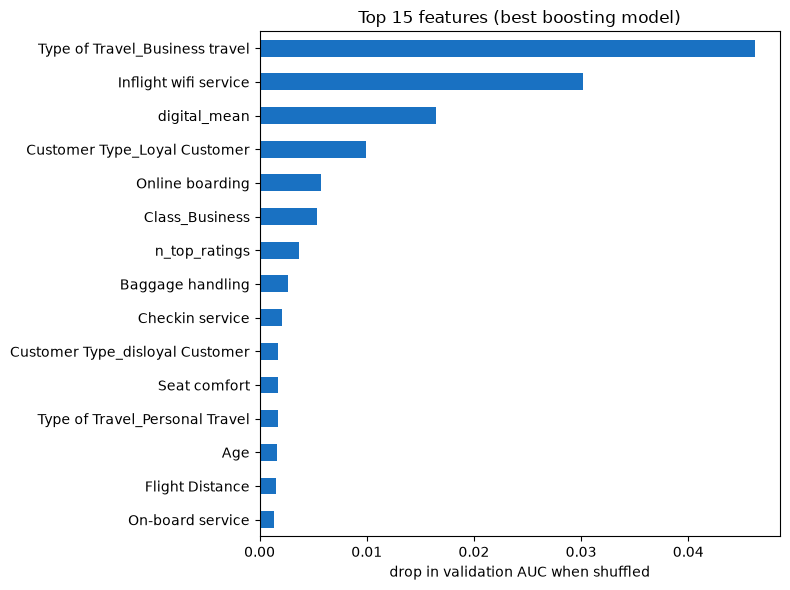

Type of Travel_Business travel     0.0462
Inflight wifi service              0.0301
digital_mean                       0.0165
Customer Type_Loyal Customer       0.0100
Online boarding                    0.0057
Class_Business                     0.0054
n_top_ratings                      0.0037
Baggage handling                   0.0026
Checkin service                    0.0021
Customer Type_disloyal Customer    0.0017
Seat comfort                       0.0017
Type of Travel_Personal Travel     0.0017
Age                                0.0016
Flight Distance                    0.0015
On-board service                   0.0013
dtype: float64

In [9]:
sample = Xf_va.sample(20_000, random_state=0)
imp = permutation_importance(best_model, sample, y_va.loc[sample.index], scoring='roc_auc',
                             n_repeats=3, random_state=0, n_jobs=-1)
importance = pd.Series(imp.importances_mean, index=sample.columns).sort_values()

fig, ax = plt.subplots(figsize=(8, 6))
importance.tail(15).plot.barh(ax=ax, color='#1971c2')
ax.set_xlabel('drop in validation AUC when shuffled')
ax.set_title('Top 15 features (best boosting model)')
plt.tight_layout(); plt.savefig('../report/figures/feature_importance_v2.png', dpi=150)
plt.show()
importance.sort_values(ascending=False).head(15).round(4)

## 9. Submission file
Refit on **all** training rows with the number of trees found by early stopping, then predict the test set.

In [10]:
final_params = dict(max_iter=best_model.n_iter_, learning_rate=0.05, max_leaf_nodes=63,
                    early_stopping=False, random_state=0)
final_params.update(best_params)
final_cat = best_model.categorical_features
hgb_full = HistGradientBoostingClassifier(categorical_features=final_cat, **final_params).fit(Xf, y)
p_test = hgb_full.predict_proba(Xf_test)[:, 1]

if use_blend:
    scaler_full = StandardScaler().fit(Xb)
    lr_full = LogisticRegression(max_iter=3000).fit(scaler_full.transform(Xb), yb)
    p_lr_test = lr_full.predict_proba(scaler_full.transform(Xb_test))[:, 1]
    p_test = (best_w * pd.Series(p_test).rank(pct=True)
              + (1 - best_w) * pd.Series(p_lr_test).rank(pct=True)).to_numpy()
    name, val_auc = 'v2_hgb_logreg_blend', blend_auc[best_w]
else:
    name, val_auc = 'v2_hgb_features', best_auc

print(save_submission(test, p_test, name))

# Kaggle description, following the README pattern
settings = ', '.join(f'{k} {v}' for k, v in final_params.items()
                     if k in ('learning_rate', 'max_leaf_nodes', 'min_samples_leaf', 'l2_regularization'))
what = 'new rating + delay features' + (', ratings as categories' if final_cat is not None else '')
what += f', rank blend {best_w:.2f}/{1-best_w:.2f} with logistic' if use_blend else ''
print('\nKaggle description:')
print(f'v2 - HistGradientBoosting, {settings}, {hgb_full.n_iter_} trees. Added {what}. Validation AUC {val_auc:.5f}.')

saved submissions\v2_hgb_features.csv

Kaggle description:
v2 - HistGradientBoosting, learning_rate 0.03, max_leaf_nodes 127, min_samples_leaf 50, l2_regularization 1.0, 397 trees. Added new rating + delay features. Validation AUC 0.95745.


## Result (run 2026-11-27): no gain, not submitted
Every v2 option scored **below** the v1 baseline on the validation split:

| Model | Validation AUC | vs baseline |
|---|---|---|
| v1 baseline boosting | 0.95758 | 0 |
| + new features | 0.95722 | -0.00036 |
| + features + ratings as categories | 0.95696 | -0.00062 |
| best of 5 tuned settings | 0.95745 | -0.00013 |
| blend with logistic regression | 0.95745 | no gain (best weight = boosting only) |

* Boosting already finds what the rating averages and delay features add, so the extra columns only add noise.
* Tuning barely matters here (0.95700 to 0.95745), so small changes to this model have hit a ceiling.
* The `v2_hgb_features.csv` file saved above is **worse than v1**, so it was deleted and not uploaded to Kaggle.
  (This notebook picks the best *new* option without comparing it to the baseline; notebook 02 fixes that.)
* Keep `src/clean.py` as it is: the features are not worth moving there.

Next step: different, stronger models (CatBoost, LightGBM) and an ensemble, in `02_khine_catboost_lightgbm.ipynb`.
